Сгенерируем 1 000 клиентов. Вероятность покупки будет зависеть от частоты покупок, среднего чека и возраста. Для разнообразия добавим случайность: даже похожие клиенты не всегда принимают одинаковое решение.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Для воспроизводимости результатов
np.random.seed(42)
rng = np.random.default_rng(42)

# Количество клиентов
n = 1000

# Генерируем признаки
data = {
    'CustomerID': range(1, n + 1),
    'Age': rng.integers(18, 71, n),
    'AveragePurchaseValue': np.clip(
        rng.normal(250, 100, n), 30, 700
    ),
    'PurchaseFrequency': np.clip(
        rng.poisson(4, n) + 1, 1, 15
    )
}

df = pd.DataFrame(data)

# Вероятность покупки зависит от характеристик клиента
logit = (
    -0.5
    + 0.12 * df['PurchaseFrequency']
    + 0.004 * (df['AveragePurchaseValue'] - 250)
    - 0.012 * (df['Age'] - 40)
)

purchase_probability = 1 / (1 + np.exp(-logit))

# Целевая переменная:
# 1 — покупка совершена, 0 — покупки нет
df['Purchase'] = rng.binomial(
    1, purchase_probability
)

# Первые строки
display(df.head(10))

# Общая информация
print('Количество клиентов:', len(df))
print('\nРаспределение целевой переменной:')
print(df['Purchase'].value_counts())
print('\nДоля совершивших покупку:')
print(round(df['Purchase'].mean() * 100, 2), '%')

,CustomerID,Age,AveragePurchaseValue,PurchaseFrequency,Purchase
0,1,22,393.321451,6,1
1,2,59,259.152018,4,0
2,3,52,308.077710,4,0
3,4,41,244.321681,8,0
4,5,40,232.959242,4,0
5,6,63,172.051760,4,1
6,7,22,293.030136,4,1
7,8,54,164.846281,12,0
8,9,28,316.558524,1,1
9,10,22,358.528700,7,0


Количество клиентов: 1000

Распределение целевой переменной:
Purchase
0    522
1    478
Name: count, dtype: int64

Доля совершивших покупку:
47.8 %


Здесь Purchase — наша целевая переменная. Мы её будем прогнозировать. Остальные три признака будут использоваться нейросетью для прогноза.
Покажем основные характеристики и распределение покупок.

Что написать в отчёте: набор содержит 1 000 клиентов, три признака покупательского поведения и одну целевую переменную. Пропуски отсутствуют, поскольку данные сгенерированы программно.
Шаг 4. Подготовка данных
Разделим данные на обучающую выборку (80%) и тестовую (20%). Масштабирование необходимо, поскольку нейронная сеть чувствительна к диапазонам значений признаков.

,CustomerID,Age,AveragePurchaseValue,PurchaseFrequency,Purchase
count,1000.00,1000.00,1000.00,1000.00,1000.00
mean,500.50,44.16,248.60,4.93,0.48
std,288.82,15.30,100.18,1.97,0.50
min,1.00,18.00,30.00,1.00,0.00
25%,250.75,31.00,181.35,4.00,0.00
50%,500.50,44.00,250.35,5.00,0.00
75%,750.25,58.00,313.58,6.00,1.00
max,1000.00,70.00,567.89,15.00,1.00


Количество пропусков:
CustomerID              0
Age                     0
AveragePurchaseValue    0
PurchaseFrequency       0
Purchase                0
dtype: int64


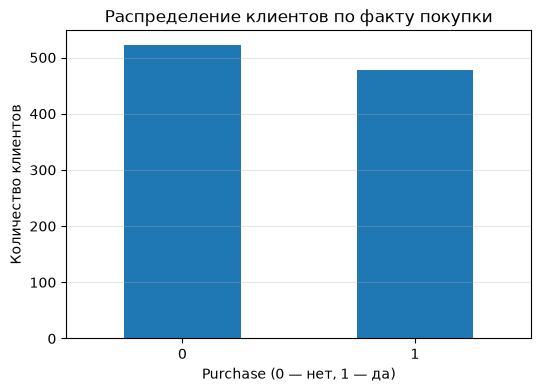

In [9]:
# Основные статистические характеристики
display(df.describe().round(2))

# Проверяем пропуски
print('Количество пропусков:')
print(df.isna().sum())

# Распределение целевой переменной
df['Purchase'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(6, 4)
)

plt.title('Распределение клиентов по факту покупки')
plt.xlabel('Purchase (0 — нет, 1 — да)')
plt.ylabel('Количество клиентов')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()

Шаг 5. Создание нейронной сети
Будем использовать TensorFlow/Keras. Архитектура будет простой: три входных признака, два скрытых слоя и один выходной нейрон.
Входной слой

3 признака клиента

Скрытый слой

16 нейронов · ReLU

Скрытый слой

8 нейронов · ReLU

Выходной слой

1 нейрон · Sigmoid · вероятность покупки

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

features = [
    'Age',
    'AveragePurchaseValue',
    'PurchaseFrequency'
]

X = df[features]
y = df['Purchase']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Масштабируем признаки.
# Обучаем scaler только на обучающей выборке,
# чтобы избежать утечки информации из тестовой.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Размер обучающей выборки:', X_train.shape)
print('Размер тестовой выборки:', X_test.shape)
print('Доля покупок в обучении:', round(y_train.mean(), 3))
print('Доля покупок в тесте:', round(y_test.mean(), 3))

Размер обучающей выборки: (800, 3)
Размер тестовой выборки: (200, 3)
Доля покупок в обучении: 0.478
Доля покупок в тесте: 0.48


Кратко о настройках:
- relu — функция активации скрытых слоёв.
- sigmoid — возвращает вероятность от 0 до 1.
- binary_crossentropy — функция ошибки для бинарной классификации.
- adam — алгоритм оптимизации весов сети.
Шаг 6. Обучение нейронной сети
Мы разрешаем обучению продолжаться до 100 эпох, но используем EarlyStopping, чтобы остановить его, если качество на валидационных данных перестаёт улучшаться.

Как интерпретировать графики: если ошибка снижается, сеть обучается. Если ошибка на обучении продолжает снижаться, а на валидации растёт, это может указывать на переобучение.
Шаг 7. Оценка нейронной сети
Теперь оценим её на тестовой выборке, которую сеть не использовала при обучении.

In [11]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(len(features),)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209 (836.00 B)

 Trainable params: 209 (836.00 B)

 Non-trainable params: 0 (0.00 B)

Основные метрики:
- Accuracy — доля правильных прогнозов.
- Precision — какая доля предсказанных покупок действительно оказалась покупками.
- Recall — какую долю реальных покупок модель смогла обнаружить.
- F1-score — баланс между Precision и Recall.
Для маркетинга особенно важны Precision и Recall: первая помогает оценивать точность отбора клиентов для рассылки, вторая — не упускать потенциальных покупателей.
Шаг 8. Обучение классической модели
В качестве классического алгоритма возьмём логистическую регрессию. Это простой и понятный алгоритм бинарной классификации.

In [12]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100


20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4703 - loss: 0.7256 - val_accuracy: 0.4563 - val_loss: 0.7276
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4969 - loss: 0.7093 - val_accuracy: 0.4812 - val_loss: 0.7126
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5391 - loss: 0.6971 - val_accuracy: 0.4875 - val_loss: 0.7025
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5703 - loss: 0.6887 - val_accuracy: 0.5188 - val_loss: 0.6961
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5828 - loss: 0.6829 - val_accuracy: 0.5250 - val_loss: 0.6920
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5859 - loss: 0.6787 - val_accuracy: 0.5437 - val_loss: 0.6892
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5922 - loss: 0.6753 - val_accuracy: 0.5437 - val_loss: 0.6872
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5938 - loss: 0.6724 - val_accuracy: 0.5500 - val_loss: 0.6

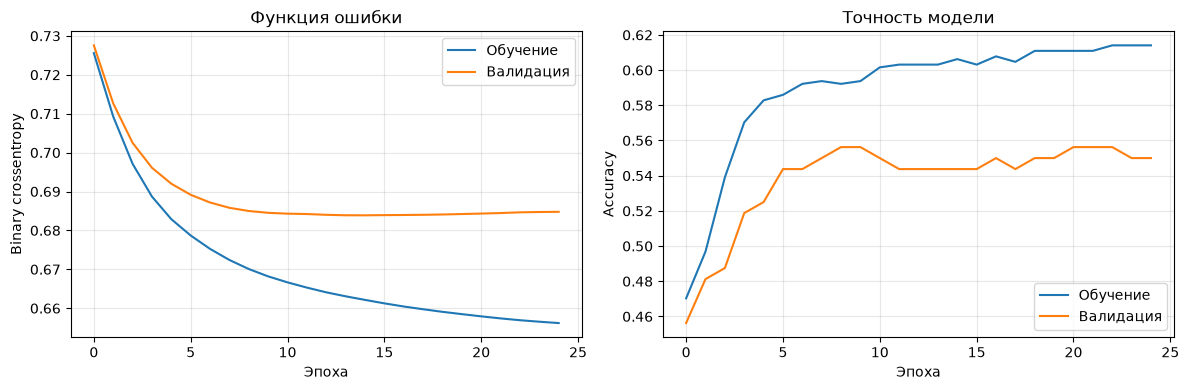

Количество завершённых эпох: 25


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Изменение ошибки
axes[0].plot(history.history['loss'], label='Обучение')
axes[0].plot(history.history['val_loss'], label='Валидация')
axes[0].set_title('Функция ошибки')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Binary crossentropy')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Изменение точности
axes[1].plot(history.history['accuracy'], label='Обучение')
axes[1].plot(history.history['val_accuracy'], label='Валидация')
axes[1].set_title('Точность модели')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print('Количество завершённых эпох:', len(history.history['loss']))

Не удивляйся, если логистическая регрессия покажет такой же или даже лучший результат. Мы сами создали данные, в которых вероятность покупки зависит от линейной комбинации признаков, поэтому классический алгоритм может оказаться очень подходящим. Это нормальный и содержательный результат эксперимента.
Шаг 10. Анализ ошибок моделей
Матрица ошибок покажет, где каждая модель ошибается.

В матрице:
- Верхний левый угол — правильно предсказанное отсутствие покупки.
- Верхний правый — ложное предсказание покупки.
- Нижний левый — пропущенная реальная покупка.
- Нижний правый — правильно найденная покупка.
Дополнительно посмотрим примеры, где прогнозы моделей различаются.

In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Вероятность покупки
nn_prob = model.predict(X_test_scaled, verbose=0).ravel()

# Преобразуем вероятность в класс:
# >= 0.5 — покупка, < 0.5 — покупки нет
nn_pred = (nn_prob >= 0.5).astype(int)

print('Метрики нейронной сети:')
print(classification_report(
    y_test,
    nn_pred,
    target_names=['Нет покупки', 'Покупка'],
    zero_division=0
))

print('Accuracy:', round(accuracy_score(y_test, nn_pred), 3))
print('Precision:', round(precision_score(y_test, nn_pred, zero_division=0), 3))
print('Recall:', round(recall_score(y_test, nn_pred, zero_division=0), 3))
print('F1-score:', round(f1_score(y_test, nn_pred, zero_division=0), 3))

Метрики нейронной сети:
              precision    recall  f1-score   support

 Нет покупки       0.61      0.61      0.61       104
     Покупка       0.57      0.57      0.57        96

    accuracy                           0.59       200
   macro avg       0.59      0.59      0.59       200
weighted avg       0.59      0.59      0.59       200

Accuracy: 0.59
Precision: 0.573
Recall: 0.573
F1-score: 0.573


In [15]:
from sklearn.linear_model import LogisticRegression

classic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

classic_model.fit(X_train_scaled, y_train)

classic_prob = classic_model.predict_proba(
    X_test_scaled
)[:, 1]

classic_pred = (classic_prob >= 0.5).astype(int)

print('Метрики логистической регрессии:')
print(classification_report(
    y_test,
    classic_pred,
    target_names=['Нет покупки', 'Покупка'],
    zero_division=0
))

Метрики логистической регрессии:
              precision    recall  f1-score   support

 Нет покупки       0.60      0.71      0.65       104
     Покупка       0.61      0.49      0.54        96

    accuracy                           0.60       200
   macro avg       0.61      0.60      0.60       200
weighted avg       0.61      0.60      0.60       200



In [16]:
results = pd.DataFrame({
    'Модель': [
        'Логистическая регрессия',
        'Нейронная сеть'
    ],
    'Accuracy': [
        accuracy_score(y_test, classic_pred),
        accuracy_score(y_test, nn_pred)
    ],
    'Precision': [
        precision_score(y_test, classic_pred, zero_division=0),
        precision_score(y_test, nn_pred, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, classic_pred, zero_division=0),
        recall_score(y_test, nn_pred, zero_division=0)
    ],
    'F1-score': [
        f1_score(y_test, classic_pred, zero_division=0),
        f1_score(y_test, nn_pred, zero_division=0)
    ]
})

display(results.round(3))

,Модель,Accuracy,Precision,Recall,F1-score
0,Логистическая регрессия,0.605,0.610,0.490,0.543
1,Нейронная сеть,0.590,0.573,0.573,0.573


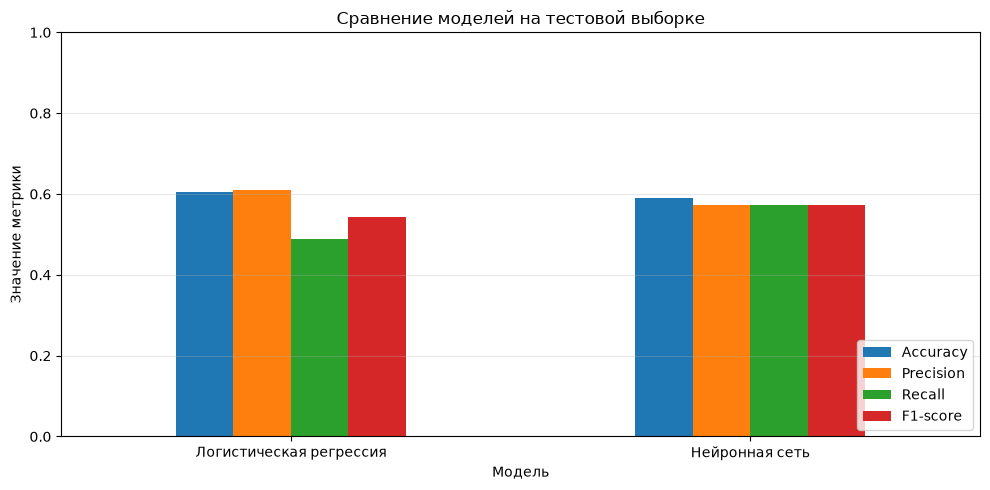

In [17]:
results.plot(
    x='Модель',
    y=['Accuracy', 'Precision', 'Recall', 'F1-score'],
    kind='bar',
    figsize=(10, 5)
)

plt.title('Сравнение моделей на тестовой выборке')
plt.ylabel('Значение метрики')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

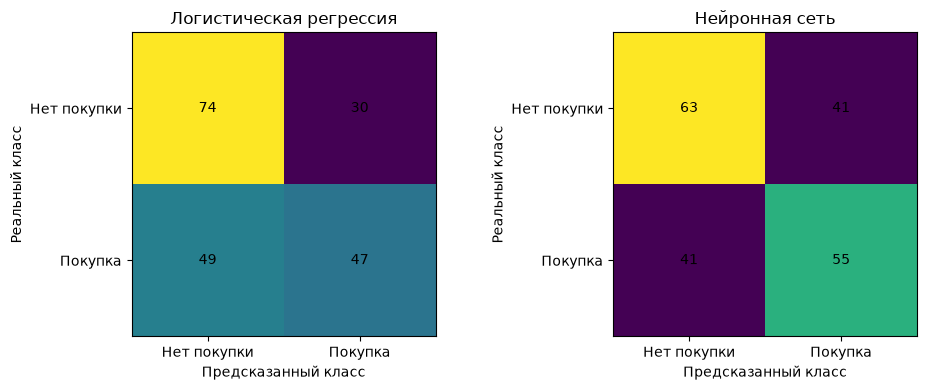

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, predictions, title in [
    (axes[0], classic_pred, 'Логистическая регрессия'),
    (axes[1], nn_pred, 'Нейронная сеть')
]:
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    ax.imshow(cm)
    ax.set_title(title)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Реальный класс')
    ax.set_xticks([0, 1], labels=['Нет покупки', 'Покупка'])
    ax.set_yticks([0, 1], labels=['Нет покупки', 'Покупка'])

    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center')

plt.tight_layout()
plt.show()

In [19]:
error_analysis = X_test.copy()

error_analysis['RealPurchase'] = y_test
error_analysis['NN_Probability'] = nn_prob
error_analysis['NN_Prediction'] = nn_pred
error_analysis['LR_Probability'] = classic_prob
error_analysis['LR_Prediction'] = classic_pred

different_predictions = error_analysis[
    error_analysis['NN_Prediction']
    != error_analysis['LR_Prediction']
]

display(different_predictions.head(20))
print('Количество клиентов с разными прогнозами:',
      len(different_predictions))

,Age,AveragePurchaseValue,PurchaseFrequency,RealPurchase,NN_Probability,NN_Prediction,LR_Probability,LR_Prediction
926,46,315.174814,3,1,0.557313,1,0.479197,0
948,68,324.549891,5,0,0.523792,1,0.495039,0
860,69,292.779640,6,1,0.511559,1,0.489534,0
128,48,303.803444,2,1,0.508946,1,0.430293,0
941,39,289.053060,3,0,0.533000,1,0.469167,0
821,53,311.427044,4,1,0.527359,1,0.488435,0
91,60,276.203581,6,1,0.505568,1,0.495122,0
63,69,224.662243,9,1,0.430796,0,0.510503,1
502,69,323.558309,10,0,0.467126,0,0.645567,1
883,26,212.031347,5,0,0.504012,1,0.482842,0


Количество клиентов с разными прогнозами: 23


# Вывод по заданию №4

В ходе работы была разработана нейронная сеть для решения задачи бинарной классификации — прогнозирования факта совершения покупки клиентом интернет-магазина.

Для исследования был сформирован синтетический набор данных из 1000 клиентов. В качестве признаков использовались возраст, средняя сумма покупки и частота покупок. Целевая переменная Purchase принимала значение 1, если покупка была совершена, и 0 в противном случае.

Перед обучением данные были разделены на обучающую и тестовую выборки. Числовые признаки масштабировались с помощью StandardScaler. Нейронная сеть состояла из двух скрытых слоёв с функцией активации ReLU и выходного слоя с функцией активации Sigmoid. Обучение проводилось с использованием функции потерь binary crossentropy и оптимизатора Adam.

Качество нейронной сети оценивалось по метрикам Accuracy, Precision, Recall и F1-score. Для сравнения была обучена классическая модель — логистическая регрессия — на тех же данных и с использованием того же разбиения на выборки.

По результатам эксперимента наилучшее значение F1-score показала **[название модели]**. Её значение F1-score составило **[значение]**, тогда как у второй модели оно составило **[значение]**.

Нейронная сеть позволяет моделировать сложные нелинейные зависимости между признаками, однако требует настройки архитектуры и параметров обучения. Логистическая регрессия проще в реализации и интерпретации и может показывать сопоставимые результаты, если зависимости в данных имеют относительно простую структуру.

Таким образом, выбор модели должен основываться на результатах тестирования, а не на предположении о том, что нейронная сеть всегда превосходит классические алгоритмы. Поскольку в данной работе использовались синтетические данные, полученные результаты не могут напрямую переноситься на реальных покупателей интернет-магазина.
